# 🔁 04 · Backpropagation for Hidden Layers

> **Module 02 – Feed-Forward Networks and Backpropagation** · Notebook 4 of 6
> Course notes: page 5, *"For deeper layers"* → $\boxed{\Delta w_{ji}=\eta\,x_i\,o_j(1-o_j)\sum_{s\in Down(j)}\delta_s\,w_{sj}}$ and *"Only need info about next layer and previous layer"* · Mitchell §4.5.3, Table 4.2

Notebook 03 trained the output layer, whose neurons have **targets**. A hidden neuron has **no target** – nobody tells us what $o_j$ should have been. So how do we know how to change its weights?

**Answer: blame flows backwards.** A hidden neuron is responsible for the errors of the neurons it feeds, in proportion to how strongly it feeds them. That single idea, applied layer by layer, is the **backpropagation algorithm** – the engine that trains every network in this repository, up to GPT.

### 🎯 What you will learn
| # | Idea |
|---|---|
| 1 | The hidden-layer error term $\delta_j=o_j(1-o_j)\sum_{s}\delta_s w_{sj}$, derived step by step |
| 2 | A **complete** backprop step on the 2-2-1 network, all numbers shown |
| 3 | The matrix recursion $\delta^{[l]}=g'(net^{[l]})\odot(W^{[l+1]})^\top\delta^{[l+1]}$ |
| 4 | A general $L$-layer backward pass, gradient-checked on every parameter |
| 5 | Why backprop is **local** and costs only ~2× a forward pass |
| 6 | The **vanishing gradient** problem, measured layer by layer |

## 0 · Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# ---------- one consistent, clean plotting style for the whole notebook ----------
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", muted="#52514e", grid="#e6e5e1")
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": C["muted"], "axes.labelcolor": C["ink"], "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.8,
    "xtick.color": C["muted"], "ytick.color": C["muted"], "legend.frameon": False,
    "lines.linewidth": 2.0, "font.size": 10.5,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
                       ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
})
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(2)

def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def softmax(Z):
    Z = Z - Z.max(axis=0, keepdims=True)
    E = np.exp(Z)
    return E / E.sum(axis=0, keepdims=True)

---
## 1 · The variables

### 📖 Notation for the whole of module 02 (same as the course notes)

| Symbol | Shape | Meaning |
|---|---|---|
| $L$ | number | number of layers with weights (hidden + output). The input is "layer 0". |
| $n_l$ | number | number of neurons in layer $l$ ($n_0$ = number of inputs) |
| $\vec x = o^{[0]}$ | $n_0\times1$ | one input example, a **column** vector |
| $w_{ji}$ | number | weight on the wire **from** neuron $i$ (layer $l-1$) **to** neuron $j$ (layer $l$). First index = destination. |
| $W^{[l]}$ | $n_l\times n_{l-1}$ | all weights of layer $l$; **row $j$** = the incoming weights of neuron $j$ (notes: $W^{h1}_{5\times4}$) |
| $b^{[l]}$ | $n_l\times1$ | biases of layer $l$, one per neuron (the weight of the constant input $x_0=1$) |
| $net^{[l]}=W^{[l]}o^{[l-1]}+b^{[l]}$ | $n_l\times1$ | net inputs of layer $l$; entry $j$ is $net_j=\sum_i w_{ji}\,o_i+b_j$ |
| $o^{[l]}=g(net^{[l]})$ | $n_l\times1$ | outputs (activations) of layer $l$; $g$ = activation function, e.g. sigmoid |
| $x_{ji}$ | number | the input that arrives at neuron $j$ from $i$, i.e. $x_{ji}=o_i$ (Mitchell / notes) |
| $t_k$ | number | target for output neuron $k$ |
| $E$ | number | the error (loss) we minimise |
| $\delta_j=-\dfrac{\partial E}{\partial net_j}$ | number | **error term** of neuron $j$ ("how much the error drops if $net_j$ rises") |
| $\eta$ | number | learning rate |
| $N$ | number | batch size; a batch is $X\in\mathbb R^{n_0\times N}$ with **one example per column** |

The notes also name layers by role: $h1$, $h2$ (hidden) and $o$ (output), e.g. $o^{h1}=\sigma(W^{h1}x+b^{h1})$.
New in this notebook:

| Symbol | Meaning |
|---|---|
| $j$ | a **hidden** neuron |
| $i$ | a neuron in the layer **before** $j$ (its input); $x_{ji}=o_i$ is the signal on the wire $i\to j$ |
| $s$ | a neuron in the layer **after** $j$ |
| $Down(j)$ | the set of neurons that receive $j$'s output ("downstream of $j$"). In a dense net: the whole next layer. |
| $w_{sj}$ | weight from $j$ to a downstream neuron $s$ |
| $\delta_s$ | error term of downstream neuron $s$ – **already known**, because we go backwards |

---
## 2 · The idea: passing the blame backwards 🫵

![hidden blame](../figures/p2_hidden_blame.png)

Neuron $j$ only affects the error **through** the neurons $s$ it feeds. Each of them already knows its blame $\delta_s$. If the wire $j\to s$ is strong ($|w_{sj}|$ large), $j$ shares a lot of $s$'s blame; if it's weak, little. Add up over all $s$, then scale by how sensitive $j$ itself is ($o_j(1-o_j)$).

---
## 3 · Derivation, following the notes step by step ✍️

**Step 1 – split at $net_j$** (same as for the output layer). $w_{ji}$ only influences $E$ through $net_j$:

$$\frac{\partial E}{\partial w_{ji}}=\frac{\partial E}{\partial net_j}\cdot\underbrace{\frac{\partial net_j}{\partial w_{ji}}}_{x_{ji}}$$

**Step 2 – $net_j$ influences $E$ through every downstream $net_s$** (multivariate chain rule: add up all paths):

$$\frac{\partial E}{\partial net_j}=\sum_{s\in Down(j)}\underbrace{\frac{\partial E}{\partial net_s}}_{-\delta_s}\cdot\frac{\partial net_s}{\partial net_j}$$

**Step 3 – one more chain through $o_j$.** Since $net_s=\sum_j w_{sj}o_j+b_s$ and $o_j=\sigma(net_j)$:

$$\frac{\partial net_s}{\partial net_j}=\underbrace{\frac{\partial net_s}{\partial o_j}}_{w_{sj}}\cdot\underbrace{\frac{\partial o_j}{\partial net_j}}_{o_j(1-o_j)}$$

**Step 4 – put it together** with $\delta_j=-\partial E/\partial net_j$:

$$\boxed{\delta_j=o_j(1-o_j)\sum_{s\in Down(j)}\delta_s\,w_{sj}}\qquad\qquad
\boxed{\Delta w_{ji}=\eta\,\delta_j\,x_{ji}=\eta\,x_{ji}\,o_j(1-o_j)\sum_{s\in Down(j)}\delta_s\,w_{sj}}$$

That second box is exactly the boxed formula in the notes. 🎉

> 💡 **Same update rule as the output layer!** $\Delta w=\eta\times\delta\times\text{input}$ everywhere. Only the way we get $\delta$ differs:
> * output neuron: $\delta_k=o_k(1-o_k)\,(t_k-o_k)$ — uses the **target**
> * hidden neuron: $\delta_j=o_j(1-o_j)\,\sum_s\delta_sw_{sj}$ — uses the **blame from downstream** instead

---
## 4 · A complete backprop step on the 2-2-1 network 🔢

Same network and numbers as notebooks 02–03: $x=(1,0.5)$, target $t=1$, $\eta=0.5$, sigmoid everywhere. Now we update **both** layers.

In [2]:
x  = np.array([[1.0], [0.5]])
W1 = np.array([[0.2, 0.4], [-0.3, 0.1]]); b1 = np.array([[0.1], [-0.1]])
W2 = np.array([[0.6, -0.2]]);              b2 = np.array([[0.05]])
t, eta = np.array([[1.0]]), 0.5

# ---------- forward: compute and STORE ----------
o1 = sigmoid(W1 @ x + b1)                    # hidden outputs o_j
o2 = sigmoid(W2 @ o1 + b2)                   # output o_k
E0 = 0.5 * np.sum((t - o2) ** 2)
print(f"forward : o_hidden = {o1.ravel().round(4)},  o_out = {o2[0, 0]:.4f},  E = {E0:.5f}")

# ---------- backward ----------
delta2 = (t - o2) * o2 * (1 - o2)            # output:  δ_k = (t_k - o_k) o_k (1 - o_k)
blame = W2.T @ delta2                        # Σ_s δ_s w_sj  for every hidden j  (here one s)
delta1 = o1 * (1 - o1) * blame               # hidden:  δ_j = o_j (1 - o_j) Σ_s δ_s w_sj
print(f"δ_out   = {delta2.ravel().round(5)}")
print(f"blame Σ δ_s w_sj = {blame.ravel().round(5)}   (= δ_out × [0.6, -0.2])")
print(f"o_j(1-o_j)       = {(o1 * (1 - o1)).ravel().round(5)}")
print(f"δ_hidden         = {delta1.ravel().round(5)}")

# ---------- update: Δw = η δ (input)^T for BOTH layers ----------
dW2, db2 = eta * delta2 @ o1.T, eta * delta2
dW1, db1 = eta * delta1 @ x.T,  eta * delta1
print("ΔW2 =", dW2.round(5).tolist(), "  ΔW1 =", dW1.round(5).tolist())

W1n, b1n, W2n, b2n = W1 + dW1, b1 + db1, W2 + dW2, b2 + db2
o2n = sigmoid(W2n @ sigmoid(W1n @ x + b1n) + b2n)
print(f"after one step: o_out {o2[0, 0]:.4f} → {o2n[0, 0]:.4f},  E {E0:.5f} → {0.5 * np.sum((t - o2n) ** 2):.5f} ✅")

forward : o_hidden = [0.6225 0.4134],  o_out = 0.5844,  E = 0.08637
δ_out   = [0.1009]
blame Σ δ_s w_sj = [ 0.0606 -0.0202]   (= δ_out × [0.6, -0.2])
o_j(1-o_j)       = [0.235  0.2425]
δ_hidden         = [ 0.0142 -0.0049]
ΔW2 = [[0.03142, 0.02086]]   ΔW1 = [[0.00712, 0.00356], [-0.00245, -0.00122]]
after one step: o_out 0.5844 → 0.6040,  E 0.08637 → 0.07842 ✅


**Read the hidden deltas.** Hidden neuron 1 connects to the output with $+0.6$: making it *more* active raises the (too low) output, so its $\delta>0$ and its incoming weights grow. Hidden neuron 2 connects with $-0.2$: being more active would *lower* the output, so its $\delta<0$ and its weights shrink. And it gets less blame because its wire is weaker. The arithmetic matches the intuition.

### ✅ Check every gradient against brute force

In [3]:
def numerical_grad(f, theta, eps=1e-6):
    """Central-difference gradient of scalar f() w.r.t. array theta (modified in place, then restored)."""
    g = np.zeros_like(theta)
    for idx in np.ndindex(theta.shape):
        old = theta[idx]
        theta[idx] = old + eps; fp = f()
        theta[idx] = old - eps; fm = f()
        theta[idx] = old
        g[idx] = (fp - fm) / (2 * eps)
    return g


def rel_err(a, b):
    return np.linalg.norm(a - b) / (np.linalg.norm(a) + np.linalg.norm(b) + 1e-12)

In [4]:
E_fn = lambda: 0.5 * np.sum((t - sigmoid(W2 @ sigmoid(W1 @ x + b1) + b2)) ** 2)
# analytic gradients are  ∂E/∂W = -δ (input)^T   (notes' sign convention δ = -∂E/∂net)
for name, analytic, arr in [("W1", -delta1 @ x.T, W1), ("b1", -delta1, b1),
                            ("W2", -delta2 @ o1.T, W2), ("b2", -delta2, b2)]:
    print(f"{name}: relative error = {rel_err(analytic, numerical_grad(E_fn, arr)):.2e}")

W1: relative error = 8.90e-10
b1: relative error = 5.08e-10
W2: relative error = 1.48e-10
b2: relative error = 1.10e-10


---
## 5 · Matrix form: one line per layer 📐

Stack the hidden deltas of layer $l$ into a vector. The sum $\sum_s\delta_s w_{sj}$ for all $j$ at once is the matrix-vector product $(W^{[l+1]})^\top\delta^{[l+1]}$ – the **same weights, used transposed**, carry the blame backwards along the same wires.

$$\boxed{\delta^{[L]}=(T-O^{[L]})\odot g'(net^{[L]})}\qquad
\boxed{\delta^{[l]}=g'\big(net^{[l]}\big)\odot\Big((W^{[l+1]})^\top\,\delta^{[l+1]}\Big)}\qquad
\boxed{\Delta W^{[l]}=\eta\,\delta^{[l]}\,(O^{[l-1]})^\top,\quad \Delta b^{[l]}=\eta\sum_{\text{cols}}\delta^{[l]}}$$

| term | shape | meaning |
|---|---|---|
| $\delta^{[l+1]}$ | $n_{l+1}\times N$ | blame of the layer above |
| $(W^{[l+1]})^\top\delta^{[l+1]}$ | $(n_l\times n_{l+1})(n_{l+1}\times N)=n_l\times N$ | blame sent back along the wires |
| $g'(net^{[l]})$ | $n_l\times N$ | how sensitive each neuron was (sigmoid: $o(1-o)$) |
| $\delta^{[l]}(O^{[l-1]})^\top$ | $n_l\times n_{l-1}$ | same shape as $W^{[l]}$ ✅ |

*Read it as:* **take the blame from the layer above, send it back through the weights, gate it by this layer's slope.**

![chain](../figures/c2_backprop_chain.png)

---
## 6 · A general $L$-layer implementation 💻

Supports sigmoid / tanh / ReLU hidden layers and two output types:
* `"sigmoid_mse"` – the notes' setting: sigmoid outputs, $E=\tfrac12\sum(t-o)^2$, $\delta^{[L]}=(T-O)\odot O\odot(1-O)$
* `"softmax_ce"` – classification: softmax outputs, $E=-\tfrac1N\sum t\log p$, $\delta^{[L]}=(T-P)/N$

In [5]:
# activation g and its slope g' written using the stored values (net, o)
ACT = {
    "sigmoid": (sigmoid,                         lambda net, o: o * (1 - o)),
    "tanh":    (np.tanh,                         lambda net, o: 1 - o ** 2),
    "relu":    (lambda z: np.maximum(0.0, z),    lambda net, o: (net > 0).astype(float)),
}


def init_params(sizes, rng, scheme="xavier"):
    """W^[l] ~ N(0, s^2) with s = sqrt(1/n_in) ('xavier') or sqrt(2/n_in) ('he', for ReLU)."""
    params = []
    for l in range(1, len(sizes)):
        s = np.sqrt((2.0 if scheme == "he" else 1.0) / sizes[l - 1])
        params.append((rng.normal(0, s, (sizes[l], sizes[l - 1])), np.zeros((sizes[l], 1))))
    return params


def forward(X, params, hidden="sigmoid", output="sigmoid_mse"):
    """X: (n_0 × N). Returns cache[l] = (net^[l], o^[l]) for l = 0..L."""
    g = ACT[hidden][0]
    cache, O = [(None, X)], X
    for l, (W, b) in enumerate(params, start=1):
        NET = W @ O + b                                            # net^[l] = W^[l] o^[l-1] + b^[l]
        if l < len(params):
            O = g(NET)                                             # hidden layer
        else:
            O = sigmoid(NET) if output == "sigmoid_mse" else softmax(NET)
        cache.append((NET, O))
    return cache


def loss(T, O, output="sigmoid_mse"):
    if output == "sigmoid_mse":
        return 0.5 * np.sum((T - O) ** 2)                          # E = 1/2 ΣΣ (t - o)^2   (notes)
    return -np.sum(T * np.log(O + 1e-12)) / T.shape[1]             # mean cross-entropy


def backward(T, params, cache, hidden="sigmoid", output="sigmoid_mse"):
    """Returns deltas δ^[l] (notes' sign: δ = -∂E/∂net) and gradients (∂E/∂W^[l], ∂E/∂b^[l])."""
    gprime = ACT[hidden][1]
    L = len(params)
    deltas, grads = [None] * (L + 1), [None] * L
    NET_L, O_L = cache[L]
    if output == "sigmoid_mse":
        delta = (T - O_L) * O_L * (1 - O_L)                        # δ_k = (t_k - o_k) o_k (1 - o_k)
    else:
        delta = (T - O_L) / T.shape[1]                             # δ_k = (t_k - p_k) / N
    for l in range(L, 0, -1):                                      # l = L, L-1, ..., 1
        deltas[l] = delta
        O_prev = cache[l - 1][1]
        grads[l - 1] = (-delta @ O_prev.T,                         # ∂E/∂W^[l] = -δ^[l] (o^[l-1])^T
                        -delta.sum(axis=1, keepdims=True))         # ∂E/∂b^[l] = -Σ_cols δ^[l]
        if l > 1:
            W = params[l - 1][0]
            NET_prev, O_prev = cache[l - 1]
            delta = gprime(NET_prev, O_prev) * (W.T @ delta)       # δ^[l-1] = g'(net) ⊙ (W^[l])^T δ^[l]
    return deltas, grads

### 🔍 Code walk-through
| Code | Maths |
|---|---|
| `delta = (T - O_L) * O_L * (1 - O_L)` | output error term $\delta^{[L]}$ |
| `for l in range(L, 0, -1)` | walk the layers **backwards** |
| `-delta @ O_prev.T` | $\partial E/\partial W^{[l]}=-\delta^{[l]}(o^{[l-1]})^\top$ |
| `W.T @ delta` | blame sent back: $\sum_s w_{sj}\delta_s$ for every $j$ |
| `gprime(NET_prev, O_prev) * (...)` | gate by the slope: $\delta^{[l-1]}=g'\odot(\cdot)$ |

Notice what each step uses: the $\delta$ of the **next** layer, the weights between the two layers, and the stored $net$/$o$ of the **current** and **previous** layers – nothing else. That's the notes' remark: *"Only need info about next layer and previous layer."*

### ✅ Gradient-check **every** parameter of a deeper network

In [6]:
sizes = [6, 8, 7, 5, 3]                                            # 3 hidden layers
X = rng.normal(size=(6, 9))                                        # 9 examples
for hidden, output in [("sigmoid", "sigmoid_mse"), ("tanh", "softmax_ce")]:
    params = init_params(sizes, rng)
    T = rng.uniform(0, 1, (3, 9)) if output == "sigmoid_mse" else np.eye(3)[:, rng.integers(0, 3, 9)]
    cache = forward(X, params, hidden, output)
    _, grads = backward(T, params, cache, hidden, output)
    E_fn = lambda: loss(T, forward(X, params, hidden, output)[-1][1], output)
    print(f"--- {hidden} hidden, {output} output ---")
    for l, ((W, b), (dW, db)) in enumerate(zip(params, grads), start=1):
        print(f"  layer {l}: W{W.shape}  dW rel.err = {rel_err(dW, numerical_grad(E_fn, W)):.1e}"
              f"   db rel.err = {rel_err(db, numerical_grad(E_fn, b)):.1e}")

--- sigmoid hidden, sigmoid_mse output ---
  layer 1: W(8, 6)  dW rel.err = 2.0e-08   db rel.err = 5.7e-08
  layer 2: W(7, 8)  dW rel.err = 1.3e-08   db rel.err = 9.6e-09
  layer 3: W(5, 7)  dW rel.err = 2.6e-09   db rel.err = 7.9e-10
  layer 4: W(3, 5)  dW rel.err = 5.9e-10   db rel.err = 6.0e-10
--- tanh hidden, softmax_ce output ---
  layer 1: W(8, 6)  dW rel.err = 8.4e-10   db rel.err = 1.4e-09
  layer 2: W(7, 8)  dW rel.err = 7.9e-10   db rel.err = 9.9e-10
  layer 3: W(5, 7)  dW rel.err = 9.0e-10   db rel.err = 4.6e-10
  layer 4: W(3, 5)  dW rel.err = 7.9e-10   db rel.err = 8.4e-11


Every relative error is below $10^{-7}$ (most around $10^{-9}$): the backward pass is correct for every layer. ✅ (We check with smooth activations; ReLU's kink at 0 can confuse finite differences.)

### What do the gradients look like?

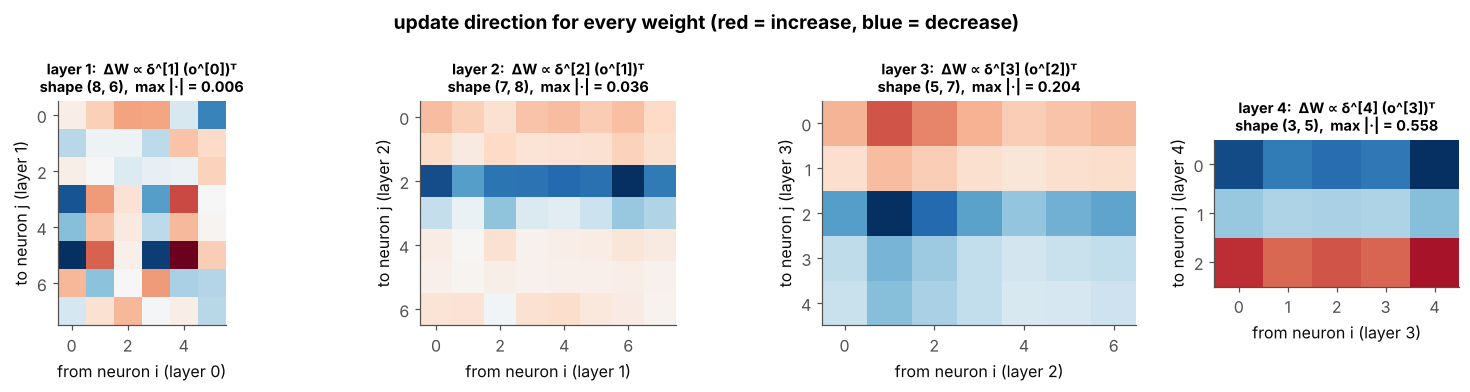

In [7]:
params = init_params([6, 8, 7, 5, 3], np.random.default_rng(5))
X = np.random.default_rng(6).normal(size=(6, 32)); T = np.random.default_rng(7).uniform(0, 1, (3, 32))
cache = forward(X, params); deltas, grads = backward(T, params, cache)

fig, axs = plt.subplots(1, 4, figsize=(14, 3.6), gridspec_kw=dict(width_ratios=[6, 8, 7, 5]))
for l, (ax, (dW, _)) in enumerate(zip(axs, grads), start=1):
    v = np.abs(dW).max()
    im = ax.imshow(-dW, cmap="RdBu_r", vmin=-v, vmax=v)            # show -∂E/∂W = direction of the update
    ax.set_title(f"layer {l}:  ΔW ∝ δ^[{l}] (o^[{l-1}])ᵀ\nshape {dW.shape},  max |·| = {v:.3f}", fontsize=9.5)
    ax.set_xlabel(f"from neuron i (layer {l-1})"); ax.set_ylabel(f"to neuron j (layer {l})"); ax.grid(False)
fig.suptitle("update direction for every weight (red = increase, blue = decrease)", fontweight="bold")
plt.tight_layout(); plt.show()

Each matrix has the **same shape as its $W^{[l]}$**, and its entries get smaller towards the input layer – a first hint of the next topic.

---
## 7 · How expensive is backprop? ⏱️

Per layer, the backward pass does **two** matrix products ($\delta(o^{[l-1]})^\top$ for the gradient and $W^\top\delta$ for the next delta); the forward pass does one. So in arithmetic, **backward ≈ 2× forward**, and a full training step ≈ 3× a forward pass – for *all* gradients at once. (Measured wall-clock time also depends on other work: below, the forward pass pays for many `exp()` calls in the sigmoid, so the two come out closer.) The brute-force alternative (`numerical_grad`) needs 2 forward passes **per parameter**.

In [8]:
import time
sizes = [784, 256, 128, 10]
params = init_params(sizes, rng)
Xb = rng.normal(size=(784, 128)); Tb = np.eye(10)[:, rng.integers(0, 10, 128)]
n_par = sum(W.size + b.size for W, b in params)

t0 = time.perf_counter()
for _ in range(20): cache = forward(Xb, params, "sigmoid", "softmax_ce")
t_fwd = (time.perf_counter() - t0) / 20
t0 = time.perf_counter()
for _ in range(20): backward(Tb, params, cache, "sigmoid", "softmax_ce")
t_bwd = (time.perf_counter() - t0) / 20
print(f"forward  {t_fwd * 1e3:6.2f} ms\nbackward {t_bwd * 1e3:6.2f} ms   (≈ {t_bwd / t_fwd:.1f}× forward on this machine)")
print(f"numerical gradient would need 2 × {n_par:,} forward passes ≈ {2 * n_par * t_fwd / 3600:.1f} hours")

forward    1.24 ms
backward   1.29 ms   (≈ 1.0× forward on this machine)
numerical gradient would need 2 × 235,146 forward passes ≈ 0.2 hours


---
## 8 · The vanishing gradient problem, measured 📉

Every step back multiplies by $g'(net)$. For the sigmoid $g'\le0.25$, so through many layers the blame **shrinks exponentially** and the early layers barely learn. tanh is better ($g'\le1$), and ReLU with He initialisation (derivative exactly 1 when active) keeps the signal healthy.

sigmoid + Xavier  ‖∂E/∂W‖ at layer 1 = 1.9e-07   at layer 11 = 8.2e-01   ratio = 2.3e-07
tanh + Xavier     ‖∂E/∂W‖ at layer 1 = 1.0e-01   at layer 11 = 1.2e-01   ratio = 8.4e-01
ReLU + He         ‖∂E/∂W‖ at layer 1 = 8.4e-01   at layer 11 = 3.7e+00   ratio = 2.2e-01


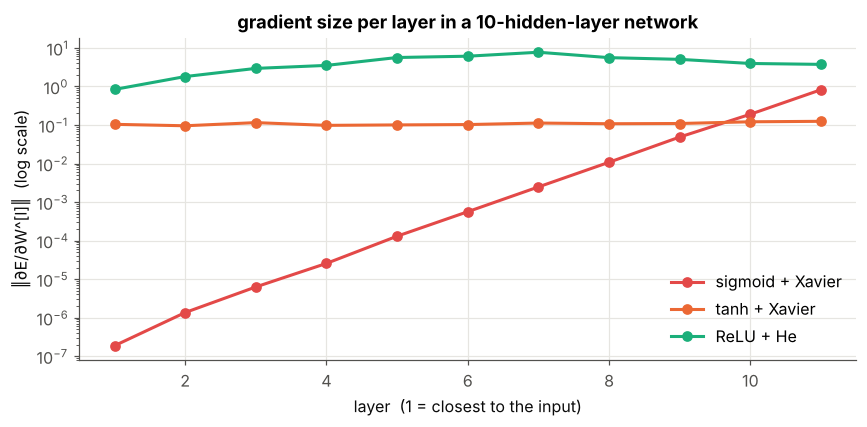

In [9]:
def layer_grad_norms(hidden, scheme, depth=10, width=50, N=256, K=5, seed=0):
    r = np.random.default_rng(seed)
    sizes = [width] + [width] * depth + [K]
    ps = init_params(sizes, r, scheme)
    X = r.normal(size=(width, N)); T = np.eye(K)[:, r.integers(0, K, N)]
    cache = forward(X, ps, hidden, "softmax_ce")
    deltas, grads = backward(T, ps, cache, hidden, "softmax_ce")
    return [np.linalg.norm(dW) for dW, _ in grads]

runs = {"sigmoid + Xavier": ("sigmoid", "xavier", C["red"]),
        "tanh + Xavier":    ("tanh", "xavier", C["orange"]),
        "ReLU + He":        ("relu", "he", C["aqua"])}
fig, ax = plt.subplots(figsize=(8, 4))
for name, (h, s, col) in runs.items():
    norms = layer_grad_norms(h, s)
    ax.semilogy(range(1, len(norms) + 1), norms, "o-", color=col, label=name)
    print(f"{name:<17} ‖∂E/∂W‖ at layer 1 = {norms[0]:.1e}   at layer {len(norms)} = {norms[-1]:.1e}   ratio = {norms[0] / norms[-1]:.1e}")
ax.set_xlabel("layer  (1 = closest to the input)"); ax.set_ylabel("‖∂E/∂W^[l]‖  (log scale)")
ax.set_title("gradient size per layer in a 10-hidden-layer network"); ax.legend()
plt.tight_layout(); plt.show()

With sigmoids the first layer's gradient is **millions of times smaller** than the last layer's: the early layers are practically frozen. This is why deep networks use ReLU-family activations and careful initialisation, and why RNNs need LSTM/GRU gates (module 06).

---
## 9 · Summary 📌

| | Output neuron $k$ | Hidden neuron $j$ |
|---|---|---|
| error term | $\delta_k=o_k(1-o_k)(t_k-o_k)$ | $\delta_j=o_j(1-o_j)\sum_{s\in Down(j)}\delta_sw_{sj}$ |
| weight update | $\Delta w_{kj}=\eta\,\delta_k\,x_{kj}$ | $\Delta w_{ji}=\eta\,\delta_j\,x_{ji}$ |
| matrix form | $\delta^{[L]}=(T-O)\odot g'$ | $\delta^{[l]}=g'(net^{[l]})\odot(W^{[l+1]})^\top\delta^{[l+1]}$ |

**The backpropagation algorithm** (Mitchell, Table 4.2): (1) forward pass, storing every $net$ and $o$; (2) $\delta$ for the output layer; (3) $\delta$ for each hidden layer, from the top down; (4) update every weight with $\Delta w=\eta\,\delta\,x$.

### ✍️ Try it yourself
1. Add `"leaky_relu"` ($g(z)=\max(0.01z,z)$) to `ACT` and run the gradient check.
2. Print $\lVert\delta^{[l]}\rVert$ (not $\lVert\partial E/\partial W\rVert$) per layer for the sigmoid network. Do they decay at the same rate?
3. Re-run the vanishing-gradient experiment with `depth=30`. Does ReLU + He stay flat?
4. In the 2-2-1 example, set $w_{s2}=0$ (the second hidden-to-output weight). What is $\delta_2$ and why?

**Next →** `05 - Training a Small Network`: put forward, backward and updates in a loop and train on real data.